# 04 — SARSA and Monte Carlo, compared with Q-learning

Same environment, same letters, same exploration schedule, same number of episodes, same seeds and
same evaluation as Q-learning (notebook 03). Only the **update rule** changes.

## SARSA (on-policy TD control, Sutton & Barto §6.4)

$$Q(S_t, A_t) \leftarrow Q(S_t, A_t) + \alpha \big[R_{t+1} + \gamma\, Q(S_{t+1}, A_{t+1}) - Q(S_t, A_t)\big]$$

The only difference with Q-learning: instead of $\max_a Q(S_{t+1}, a)$, the target uses
$A_{t+1}$, **the action the agent will actually play next** (chosen ε-greedily). SARSA therefore learns
the value of the policy it really follows, exploration included: it is **on-policy**.
(Name: it uses $S_t, A_t, R_{t+1}, S_{t+1}, A_{t+1}$.)

```
For each episode:
    S <- reset();  A <- epsilon-greedy(Q(S, .))
    Repeat:
        take A, observe R, S'
        if STOP:  Q(S, A) <- Q(S, A) + alpha [R - Q(S, A)];  end of episode
        A' <- epsilon-greedy(Q(S', .))
        Q(S, A) <- Q(S, A) + alpha [R + gamma Q(S', A') - Q(S, A)]
        S, A <- S', A'          (until STOP or 50 steps)
```

## Monte Carlo control (on-policy, first-visit, course chapter 5)

The agent plays a **whole episode** without learning, then goes backwards and computes the return
after each step, $G_t = R_{t+1} + \gamma\, G_{t+1}$. For the **first visit** of each pair $(s, a)$:

- **sample average** (course formula): $N(s,a) \leftarrow N(s,a) + 1,\quad Q(s,a) \leftarrow Q(s,a) + \frac{1}{N(s,a)}\big[G - Q(s,a)\big]$,
  i.e. $Q(s,a)$ = average of all the returns observed after $(s, a)$;
- **constant step size**: $Q(s,a) \leftarrow Q(s,a) + \alpha\big[G - Q(s,a)\big]$.

The sample average gives the same weight to every return, even to the old ones collected when the
agent was playing at random; the constant step size forgets them gradually, which suits a policy that
keeps changing (course chapter 2, *tracking a nonstationary problem*).
Monte Carlo needs episodes that end: episodes cut at 50 steps give an incomplete return (approximation).

```
For each episode:
    play S0, A0, R1, ..., S_{T-1}, A_{T-1}, R_T with the epsilon-greedy policy
    G <- 0
    for t = T-1 down to 0:
        G <- R_{t+1} + gamma G
        if (S_t, A_t) is visited for the first time at step t:
            Q(S_t, A_t) <- Q(S_t, A_t) + step * [G - Q(S_t, A_t)]      (step = 1/N or alpha)
```

## Comparison conditions

| | Q-learning | SARSA | MC (average) | MC (constant α) |
|---|---|---|---|---|
| policy type | off-policy | on-policy | on-policy | on-policy |
| update | after each step | after each step | end of episode | end of episode |
| target | $R + \gamma \max_a Q(S', a)$ | $R + \gamma Q(S', A')$ | full return $G$ | full return $G$ |
| step size | α = 0.5 | α = 0.1 | 1/N | α = 0.05 |

Common to all: γ = 0.99, ε from 1 to 0.05 over 80 % of the episodes, 30,000 episodes, 5 seeds,
greedy policy evaluated every 500 episodes. The step sizes are chosen in section 1.

In [1]:
import sys
sys.path.insert(0, "..")

import csv
import time
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import Image

from src.letters import TRAINING_LETTERS
from src.environment import LetterWritingEnv, Rewards, action_name, STOP
from src.tabular_agents import q_learning, sarsa, monte_carlo
from src.dynamic_programming import value_iteration
from src.evaluation import play_policy, greedy_policy
from src.visualization import plot_episodes, animate_episodes, SURFACE, TEXT, MUTED

GAMMA = 0.99
N_EPISODES = 30_000
SEEDS = [0, 1, 2, 3, 4]

# Optimal returns (notebook 02) and Q-learning results (notebook 03) must have been computed first
optimal = {}
with open("../results/02_optimal_returns.csv") as f:
    for row in csv.DictReader(f):
        optimal.setdefault(row["letter"], []).append(float(row["v_star"]))
v_star_mean = {name: np.mean(v) for name, v in optimal.items()}

q_curves = np.load("../results/03_q_learning_curves.npz")
with open("../results/03_q_learning_summary.csv") as f:
    q_time = {row["letter"]: float(row["time_per_run_s"]) for row in csv.DictReader(f)}

METHODS = ["Q-learning", "SARSA", "MC (average)", "MC (constant α)"]
COLORS = {"Q-learning": "#2a78d6", "SARSA": "#eb6834", "MC (average)": "#1baf7a", "MC (constant α)": "#eda100"}


def style(ax, title=None, xlabel=None, ylabel=None):
    ax.set_facecolor(SURFACE)
    ax.grid(axis="y", color="#ecebe7", lw=0.8)
    ax.tick_params(colors=MUTED, labelsize=8)
    for side in ("top", "right"):
        ax.spines[side].set_visible(False)
    for side in ("left", "bottom"):
        ax.spines[side].set_color("#c3c2b7")
    if title:
        ax.set_title(title, color=TEXT, fontsize=10)
    if xlabel:
        ax.set_xlabel(xlabel, color=MUTED, fontsize=9)
    if ylabel:
        ax.set_ylabel(ylabel, color=MUTED, fontsize=9)

## 1. Choosing the step size α

The best α depends on the algorithm. We test a few values on L and E (one run each, about 40 s).
*final* = greedy return at the end of training, *best* = best greedy return seen during training,
both as a percentage of the optimum.

In [2]:
tests = [("SARSA", sarsa, 0.5), ("SARSA", sarsa, 0.2), ("SARSA", sarsa, 0.1),
         ("MC (constant α)", monte_carlo, 0.1), ("MC (constant α)", monte_carlo, 0.05), ("MC (constant α)", monte_carlo, 0.02)]
print(f"{'method':<17}{'alpha':>6}{'L final':>10}{'L best':>9}{'E final':>10}{'E best':>9}")
for method, fn, alpha in tests:
    line = f"{method:<17}{alpha:>6}"
    for name in ["L", "E"]:
        res = fn(LetterWritingEnv(name), n_episodes=N_EPISODES, alpha=alpha, gamma=GAMMA, seed=0)
        line += f"{100 * res['eval_return'][-1] / v_star_mean[name]:>9.0f}%{100 * res['eval_return'].max() / v_star_mean[name]:>8.0f}%"
    print(line)

method            alpha   L final   L best   E final   E best
SARSA               0.5       -8%      97%      -17%      77%
SARSA               0.2       97%     100%       98%      98%
SARSA               0.1      100%     100%       99%      99%
MC (constant α)     0.1      -54%     -41%      -39%     -23%
MC (constant α)    0.05      -54%     -54%      -67%     -36%
MC (constant α)    0.02      -66%     -66%      -58%     -52%


**SARSA:** with α = 0.5 (the value used for Q-learning), SARSA learns L but then gets worse at the
end of training. The Q-learning target $R + \gamma \max_a Q(S', a)$ is stable, while the SARSA target
$R + \gamma Q(S', A')$ depends on $A'$, which is sometimes a random exploratory action: it is noisy,
and a large α makes the estimates oscillate. We keep **α = 0.1**.

**Monte Carlo:** whatever α, the greedy return stays negative. Section 4 explains why. We keep
**α = 0.05** for the constant-step version (the choice does not change the conclusion).

## 2. The 10 letters, 5 runs each

150 trainings (SARSA, MC average, MC constant α). Q-learning results are loaded from notebook 03
(same seeds, so re-running it would give exactly the same numbers). **This cell takes about 8 minutes.**

In [3]:
CONFIG = {"SARSA": (sarsa, 0.1), "MC (average)": (monte_carlo, None), "MC (constant α)": (monte_carlo, 0.05)}
runs = {m: {} for m in CONFIG}
t_all = time.perf_counter()
for name in TRAINING_LETTERS:
    for method, (fn, alpha) in CONFIG.items():
        runs[method][name] = []
        for seed in SEEDS:
            res = fn(LetterWritingEnv(name), n_episodes=N_EPISODES, alpha=alpha, gamma=GAMMA, seed=seed)
            res["policy"] = greedy_policy(res.pop("Q"))   # keep the policy only (memory)
            runs[method][name].append(res)
    print(f"{name}: " + "   ".join(f"{m} {np.mean([r['time'] for r in runs[m][name]]):.1f} s/run" for m in CONFIG))
print(f"total: {time.perf_counter() - t_all:.0f} s")

episodes = q_curves["episodes"]
curves = {"Q-learning": {name: q_curves[f"{name}_return"] for name in TRAINING_LETTERS}}
perfect = {"Q-learning": {name: q_curves[f"{name}_perfect"] for name in TRAINING_LETTERS}}
for method in CONFIG:
    curves[method] = {name: np.array([r["eval_return"] for r in rs]) for name, rs in runs[method].items()}
    perfect[method] = {name: np.array([r["eval_perfect"] for r in rs]) for name, rs in runs[method].items()}

I: SARSA 2.7 s/run   MC (average) 0.6 s/run   MC (constant α) 0.7 s/run
L: SARSA 2.2 s/run   MC (average) 0.7 s/run   MC (constant α) 0.8 s/run
T: SARSA 2.7 s/run   MC (average) 0.6 s/run   MC (constant α) 0.9 s/run
E: SARSA 3.8 s/run   MC (average) 1.6 s/run   MC (constant α) 1.9 s/run
F: SARSA 2.7 s/run   MC (average) 0.8 s/run   MC (constant α) 0.9 s/run
H: SARSA 3.9 s/run   MC (average) 1.4 s/run   MC (constant α) 2.5 s/run
N: SARSA 3.3 s/run   MC (average) 1.5 s/run   MC (constant α) 2.6 s/run
Z: SARSA 3.3 s/run   MC (average) 1.5 s/run   MC (constant α) 2.3 s/run
V: SARSA 2.3 s/run   MC (average) 0.6 s/run   MC (constant α) 0.9 s/run
X: SARSA 9.6 s/run   MC (average) 1.5 s/run   MC (constant α) 1.6 s/run
total: 313 s


### Summary table

For each method: final greedy return as a % of the optimum (mean over the 5 runs) and fraction of
(run, starting point) pairs where the final greedy policy draws the letter perfectly.

In [4]:
def first_perfect(p):
    hits = np.flatnonzero(p == 1)
    return episodes[hits[0]] if len(hits) else np.nan

rows = []
header = f"{'letter':<7}" + "".join(f"{m:>20}" for m in METHODS)
print("% of optimum v*  (mean over 5 runs)")
print(header)
for name in TRAINING_LETTERS:
    print(f"{name:<7}" + "".join(f"{100 * curves[m][name][:, -1].mean() / v_star_mean[name]:>19.0f}%" for m in METHODS))
print("\nperfect drawings at the end (fraction of runs x starting points)")
print(header)
for name in TRAINING_LETTERS:
    print(f"{name:<7}" + "".join(f"{perfect[m][name][:, -1].mean():>20.0%}" for m in METHODS))
print("\nepisodes before the first perfect drawing from every start (median over runs, '-' = never)")
print(header)
for name in TRAINING_LETTERS:
    cells_ = []
    for m in METHODS:
        med = np.nanmedian([first_perfect(p) for p in perfect[m][name]]) if any((p == 1).any() for p in perfect[m][name]) else np.nan
        cells_.append(f"{med:>20,.0f}" if not np.isnan(med) else f"{'-':>20}")
    print(f"{name:<7}" + "".join(cells_))
print("\ntraining time per run (s)")
print(header)
for name in TRAINING_LETTERS:
    times = [q_time[name]] + [np.mean([r["time"] for r in runs[m][name]]) for m in CONFIG]
    print(f"{name:<7}" + "".join(f"{t:>20.1f}" for t in times))

for name in TRAINING_LETTERS:
    for m in METHODS:
        rows.append({"letter": name, "method": m,
                     "pct_optimum_mean": round(100 * curves[m][name][:, -1].mean() / v_star_mean[name], 2),
                     "pct_optimum_std": round(100 * curves[m][name][:, -1].std() / v_star_mean[name], 2),
                     "perfect_final": round(perfect[m][name][:, -1].mean(), 3)})
with open("../results/04_comparison_summary.csv", "w", newline="", encoding="utf-8") as f:
    writer = csv.DictWriter(f, fieldnames=rows[0].keys())
    writer.writeheader()
    writer.writerows(rows)
print("\nsaved: results/04_comparison_summary.csv")

% of optimum v*  (mean over 5 runs)
letter           Q-learning               SARSA        MC (average)     MC (constant α)
I                       97%                 95%                -73%                -72%
L                      100%                100%                -30%                -56%
T                       97%                 97%                -67%                -67%
E                       97%                 99%                -24%                -53%
F                       98%                 98%                -49%                -82%
H                       93%                 94%                -45%                -32%
N                       98%                 84%                -21%                -32%
Z                       99%                100%                -16%                -18%
V                       99%                100%                -59%                -71%
X                       97%                 97%                -94%                -

### Learning curves

Mean greedy return over the 5 runs, for the four methods (dashed: optimum $v_*$).

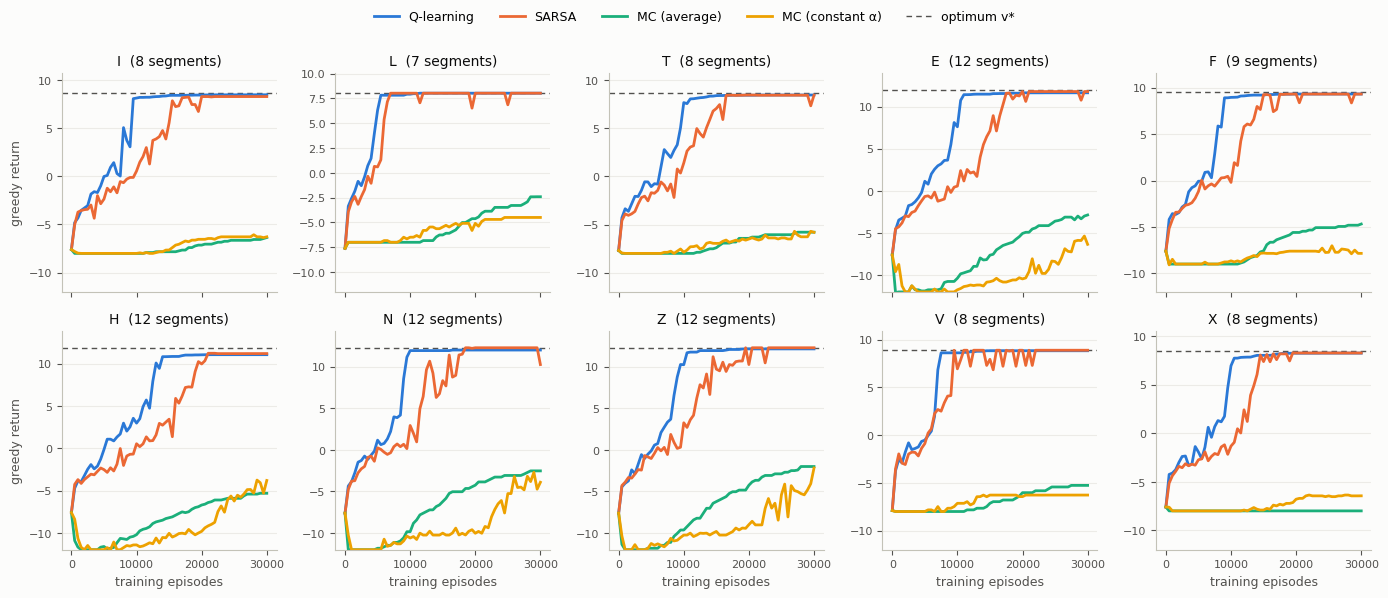

In [5]:
fig, axes = plt.subplots(2, 5, figsize=(14, 6), sharex=True, facecolor=SURFACE)
for ax, name in zip(axes.ravel(), TRAINING_LETTERS):
    ax.axhline(v_star_mean[name], color=MUTED, lw=1, ls=(0, (4, 3)))
    for m in METHODS:
        ax.plot(episodes, curves[m][name].mean(0), color=COLORS[m], lw=2)
    ax.set_ylim(-12, v_star_mean[name] + 2)
    style(ax, f"{name}  ({LetterWritingEnv(name).k} segments)")
for ax in axes[1]:
    ax.set_xlabel("training episodes", color=MUTED, fontsize=9)
for ax in axes[:, 0]:
    ax.set_ylabel("greedy return", color=MUTED, fontsize=9)
handles = [plt.Line2D([], [], color=COLORS[m], lw=2) for m in METHODS] + [plt.Line2D([], [], color=MUTED, lw=1, ls=(0, (4, 3)))]
fig.legend(handles, METHODS + ["optimum v*"], loc="upper center", ncol=5, frameon=False, fontsize=9)
fig.tight_layout(rect=(0, 0, 1, 0.94))
fig.savefig("../results/04_learning_curves.png", dpi=150, facecolor=SURFACE)
plt.show()

### Final drawings

Greedy policy of run 0 after training, from the first natural starting point: SARSA (first two rows),
then Monte Carlo with the sample average (last two rows).

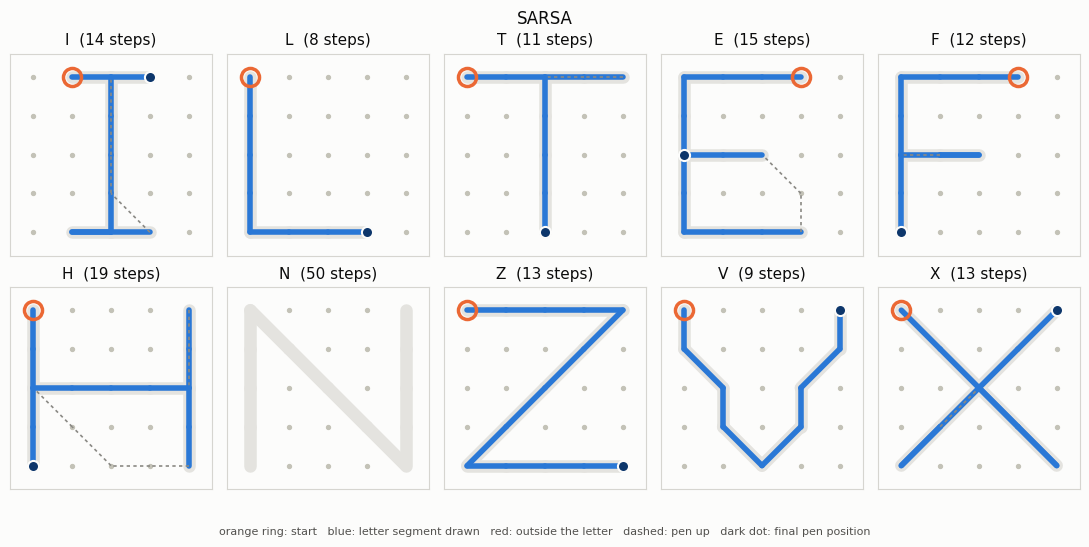

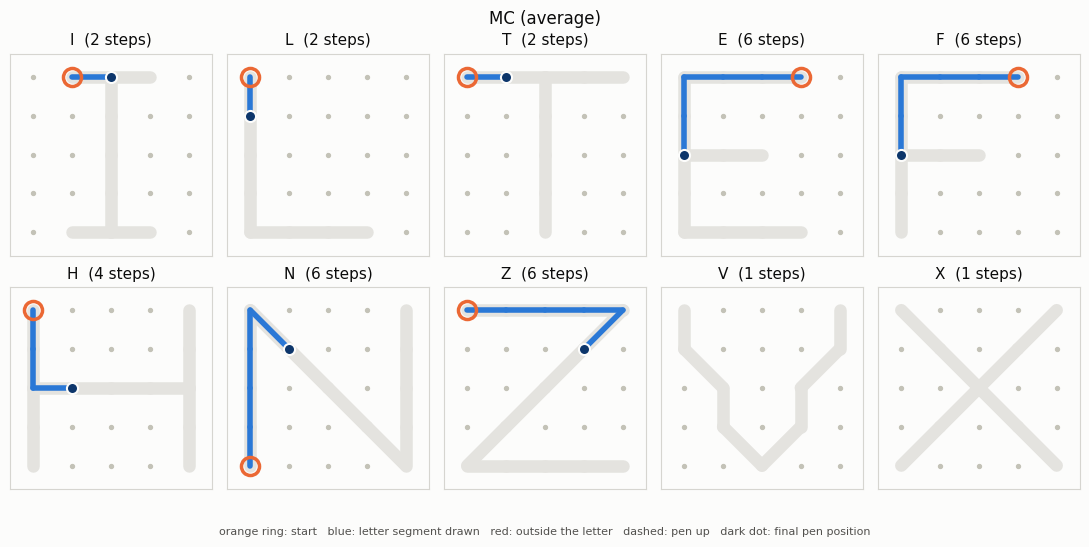

In [6]:
for method in ["SARSA", "MC (average)"]:
    panels = []
    for name in TRAINING_LETTERS:
        env = LetterWritingEnv(name)
        ep = play_policy(env, runs[method][name][0]["policy"], env.letter.start_points[0], gamma=GAMMA)
        panels.append((env.letter, ep["history"], f"{name}  ({ep['steps']} steps)"))
    tag = "sarsa" if method == "SARSA" else "mc"
    fig = plot_episodes(panels, path=f"../results/04_final_drawings_{tag}.png")
    fig.suptitle(method, color=TEXT, fontsize=12, y=1.02)
    plt.show()

## 3. On-policy vs off-policy: what the agent does *during* training

The greedy return measures the policy the agent would follow *without* exploration. The training
return measures what it actually collects *while* exploring (ε > 0). Q-learning (off-policy) learns
the greedy policy and ignores the cost of its own exploration; SARSA (on-policy) learns the value of
the ε-greedy policy it follows, exploration included. We compare both on L and E (run 0; Q-learning is
re-run here because notebook 03 did not save its training returns, about 10 s).

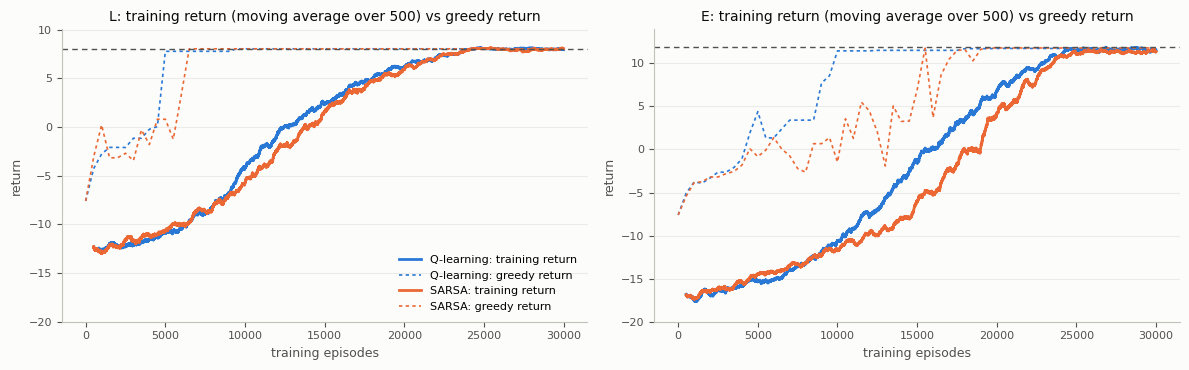

L: mean training return over the last 5,000 episodes (ε = 0.05):  Q-learning 8.00   SARSA 7.95
E: mean training return over the last 5,000 episodes (ε = 0.05):  Q-learning 11.60   SARSA 11.35


In [7]:
window = 500
q_runs = {}
fig, axes = plt.subplots(1, 2, figsize=(12, 3.8), facecolor=SURFACE)
for ax, name in zip(axes, ["L", "E"]):
    res_q = q_runs[name] = q_learning(LetterWritingEnv(name), n_episodes=N_EPISODES, alpha=0.5, gamma=GAMMA, seed=0)
    res_s = runs["SARSA"][name][0]
    for m, res in [("Q-learning", res_q), ("SARSA", res_s)]:
        smooth = np.convolve(res["train_returns"], np.ones(window) / window, mode="valid")
        ax.plot(np.arange(window, N_EPISODES + 1), smooth, color=COLORS[m], lw=2, label=f"{m}: training return")
        ax.plot(res["eval_episodes"], res["eval_return"], color=COLORS[m], lw=1.2, ls=(0, (2, 2)),
                label=f"{m}: greedy return")
    ax.axhline(v_star_mean[name], color=MUTED, lw=1, ls=(0, (4, 3)))
    ax.set_ylim(-20, v_star_mean[name] + 2)
    style(ax, f"{name}: training return (moving average over {window}) vs greedy return", "training episodes", "return")
axes[0].legend(frameon=False, fontsize=8, loc="lower right")
fig.tight_layout()
fig.savefig("../results/04_on_vs_off_policy.png", dpi=150, facecolor=SURFACE)
plt.show()

for name in ["L", "E"]:
    tq = q_runs[name]["train_returns"][-5000:].mean()
    ts = runs["SARSA"][name][0]["train_returns"][-5000:].mean()
    print(f"{name}: mean training return over the last 5,000 episodes (ε = 0.05):  Q-learning {tq:.2f}   SARSA {ts:.2f}")

## 4. Why does Monte Carlo fail? The "giving up" trap

Let us look at what the Monte Carlo agent (sample average, run 0) has learned for L, from a starting point.

In [8]:
env = LetterWritingEnv("L")
start = env.letter.start_points[0]
s0 = env.encode(*start, 0, 0)
ep = play_policy(env, runs["MC (average)"]["L"][0]["policy"], start, gamma=GAMMA)
print("Monte Carlo greedy episode on L:", " -> ".join(
    "STOP" if info["event"] == "stop" else f"{info['from']}->{info['to']} ({'pen down' if info['pen_down'] else 'pen up'})"
    for info in ep["history"]))
print(f"segments drawn: {ep['drawn']} / {env.k}, return {ep['discounted_return']:.2f}")

# Value of stopping immediately vs continuing at random, from the start
rng = np.random.default_rng(0)
random_returns = []
for _ in range(2000):
    env.reset(start=start)
    total, done, t = 0.0, False, 0
    while not done:
        _, r, term, trunc, _ = env.step(int(rng.integers(env.n_actions)))
        total += GAMMA**t * r
        t += 1
        done = term or trunc
    random_returns.append(total)
print(f"\nfrom {start}: STOP immediately = {env.transition(s0, STOP)[1]:.1f}   "
      f"playing at random = {np.mean(random_returns):.1f} on average   optimum v* = {v_star_mean['L']:.1f}")

Monte Carlo greedy episode on L: (0, 0)->(1, 0) (pen down) -> STOP
segments drawn: 1 / 7, return -5.29

from (0, 0): STOP immediately = -7.0   playing at random = -11.0 on average   optimum v* = 8.0


**The trap.** At the beginning the agent plays at random, and continuing at random is worth about −10
on average, while stopping immediately costs only −7 (−1 per missing segment of L). Monte Carlo judges
"continue" by the returns its *current* policy actually obtained — that is, by random scribbling — so it
concludes that stopping early is better. Its policy then stops early, the returns of "continue" stay bad,
and it never gets out: it learns to draw one segment and press STOP.

Q-learning avoids the trap thanks to the max: its target $R + \gamma \max_a Q(S', a)$ values the *best*
continuation, not the random one, so as soon as a good continuation has been found once, it propagates.
SARSA is also on-policy, but it **bootstraps**: its target $R + \gamma Q(S', A')$ uses the current
estimate of the next step, which improves as soon as the agent gets better at the later steps. A Monte
Carlo return, on the contrary, records the whole rest of the episode as it was actually played — mostly
random moves at the beginning — and with the sample average these old returns are never forgotten.

## 5. What if stopping early were penalised more?

The trap comes from the reward: stopping early (−1 per missing segment) is less bad than scribbling.
We re-run Monte Carlo (sample average) and Q-learning with a penalty of **−3 per missing segment**,
everything else unchanged. The optimum changes too, so value iteration is re-run first.
One run per letter (seed 0). **This cell takes about 3 minutes.**

In [9]:
strict = Rewards(stop_missing=-3.0)
print(f"{'letter':<7}{'MC (average)':>15}{'Q-learning':>13}     (% of the new optimum; perfect drawing)")
strict_rows = []
for name in TRAINING_LETTERS:
    env = LetterWritingEnv(name, rewards=strict)
    vi = value_iteration(env, gamma=GAMMA)
    v_new = np.mean([vi["V"][s] for s in env.start_states()])
    res_mc = monte_carlo(LetterWritingEnv(name, rewards=strict), n_episodes=N_EPISODES, alpha=None, gamma=GAMMA, seed=0)
    res_q = q_learning(LetterWritingEnv(name, rewards=strict), n_episodes=N_EPISODES, alpha=0.5, gamma=GAMMA, seed=0)
    pm, pq = 100 * res_mc["eval_return"][-1] / v_new, 100 * res_q["eval_return"][-1] / v_new
    print(f"{name:<7}{pm:>10.0f}% {'✓' if res_mc['eval_perfect'][-1] == 1 else '✗':>3}{pq:>9.0f}% {'✓' if res_q['eval_perfect'][-1] == 1 else '✗':>3}")
    strict_rows.append({"letter": name, "mc_pct": round(pm, 1), "q_pct": round(pq, 1)})

letter    MC (average)   Q-learning     (% of the new optimum; perfect drawing)
I              48%   ✗       97%   ✓
L             100%   ✓      100%   ✓
T              25%   ✗       98%   ✓
E              60%   ✗       98%   ✓
F              27%   ✗       97%   ✓
H               8%   ✗       93%   ✓
N              74%   ✗       97%   ✓
Z             100%   ✓      100%   ✓
V             100%   ✓      100%   ✓
X             -66%   ✗       96%   ✓


## What to notice

(The numbers below come from our test run; yours should be very close, since the seeds are fixed.)

### SARSA: as good as Q-learning in the end, but slower and less stable
- **Final quality is similar**: 84–100 % of the optimum (Q-learning: 93–100 %), and perfect drawings in
  90–100 % of the cases (only N is sometimes imperfect).
- **It learns more slowly**: the first perfect drawing from every start comes after 6,500–19,500 episodes,
  about 1.5 times more than Q-learning (5,000–12,500).
- **It is less stable**: its curves show sudden drops, even at the end of training (L, V, N). A noisy update
  can change which action is the best in a state, and the greedy policy changes with it.
- **It needs a smaller step size**: with α = 0.5 it learns and then degrades (section 1); α = 0.1 works.

### "SARSA is more cautious": not confirmed here
At the end of training the training returns are almost equal (L: Q-learning 8.00, SARSA 7.95; E: 11.60 vs
11.35), Q-learning being even slightly higher. The classic difference (cliff walking, Sutton & Barto,
Example 6.6) appears when an exploratory mistake near a dangerous region is very costly, so that on-policy
SARSA learns a safer path. In our environment a random move costs at most −1.35 and can be repaired by the
next moves: there is no "cliff", so the safest drawing is also the optimal one. **The difference between
on-policy and off-policy depends on the environment** — a good point for the debate.

### Monte Carlo fails on every letter: the "giving up" trap
- With both versions, the greedy return stays negative on every letter, and the final policy almost never
  draws a letter (MC average: 10 % for L, 0 % elsewhere). The drawings show it: the agent draws one to five
  segments and presses STOP (for V and X it presses STOP immediately).
- **Cause** (section 4): from the start, playing at random is worth about −11 while stopping immediately
  costs −7 (for L). Judged by the returns of its own, mostly random, policy, "continue" looks worse than
  "stop". Q-learning escapes thanks to the max, SARSA thanks to bootstrapping.
- **Sample average vs constant step**: both fail. The sample average improves slowly but steadily (its
  curves keep rising), the constant step is noisier. The problem here is not that old returns are kept, but
  the trap itself.
- **With a stronger early-stop penalty (−3 per missing segment)**, Monte Carlo learns L, Z and V perfectly and
  part of the other letters, but still fails on X; Q-learning is not affected (93–100 %). The trap is an
  **interaction between the reward and the algorithm**, and Monte Carlo remains much less efficient: one
  return per episode, high variance, updates only at the end (course chapter 5, downsides of MC).
- Monte Carlo is the fastest per run, but only because its episodes are very short (it stops early): this
  is not a real advantage.

### For the debate
| | Strength seen in our experiments | Weakness seen in our experiments |
|---|---|---|
| **Q-learning** | fastest to learn (≈5,000–12,500 episodes), stable, 93–100 % of v* | not exactly optimal (exploration) |
| **SARSA** | same final quality as Q-learning | ≈1.5× slower, unstable curves, needs a smaller α; no "caution" advantage here (no cliff) |
| **Monte Carlo** | simplest idea (average of returns), no bootstrapping | falls into the "giving up" trap; even with a stronger penalty, learns only some letters in 30,000 episodes |

Next step (6): experiments on the reward itself (stroke penalty, early-stop penalty), which we now know
can change not only the writing style but also which algorithms are able to learn.
